# 03 – Main models: sentence embeddings, fine-tuned bi-encoder, fine-tuned DistilBERT

**Baseline to beat:** TF-IDF (char 2–5) + Logistic Regression, test accuracy@1 = 0.823 (notebook 02).

| ID | Model | Trained? |
|---|---|---|
| M1 | MiniLM (`all-MiniLM-L6-v2`) embeddings, nearest question / answer | No (frozen, pretrained only) |
| M2 | MiniLM fine-tuned with MultipleNegativesRankingLoss (bi-encoder) | Yes |
| M3 | PubMedBERT embeddings (`NeuML/pubmedbert-base-embeddings`), frozen and fine-tuned | Both |
| M4 | DistilBERT + classification layer (`distilbert-base-uncased`) | Yes |

**Experiments**
1. Baselines vs frozen vs fine-tuned models
2. Matching the question to training **questions** (q2q) vs to **answers** (q2a), and which pairs to train on
3. General-domain model (MiniLM) vs biomedical model (PubMedBERT)
4. Training data size: 25% / 50% / 100%

**Protocol (same as notebook 02):** train on `train`, early-stop and choose on `val`, report `test`.

**Runtime:** a GPU is strongly recommended (Colab: Runtime → Change runtime type → T4 GPU; or an Apple Silicon Mac).

## 0. Setup (works locally and on Google Colab)

In [1]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Eddydev-ALU/ML_Technique_I_Summative_sti-qa-assistant.git"

if IN_COLAB:
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    # Colab already has torch; install the rest at the versions used in this project
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers==6.1.0",
                    "transformers==5.20.0", "rank_bm25==0.2.2", "openpyxl==3.1.5"], check=True)
    subprocess.run([sys.executable, "-m", "src.download_data"], check=True)
    subprocess.run([sys.executable, "-m", "src.data_prep"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /content/repo


In [2]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.baselines import TfidfLogRegBaseline
from src.data_prep import load_prepared
from src.evaluate import RESULTS_FILE, save_result
from src.models import EmbeddingRetriever, get_device
from src.train import evaluate_model, free_memory, set_seed, train_bi_encoder, train_classifier

SEED = 42
set_seed(SEED)
print("Device:", get_device(), "| torch", torch.__version__)
if get_device() == "cpu":
    print("WARNING: no GPU found. On Colab: Runtime -> Change runtime type -> T4 GPU, then run again.")

MINILM = "sentence-transformers/all-MiniLM-L6-v2"
PUBMEDBERT = "NeuML/pubmedbert-base-embeddings"
DISTILBERT = "distilbert/distilbert-base-uncased"
MAX_EPOCHS = 8   # upper limit; early stopping usually stops sooner
PATIENCE = 2     # stop after 2 epochs without val improvement

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/training_logs", exist_ok=True)
os.makedirs("models", exist_ok=True)  # fine-tuned models (git-ignored)
pd.set_option("display.max_colwidth", 100)

Device: cuda | torch 2.11.0+cu130


## 1. Data

In [3]:
questions, answer_bank = load_prepared()
train = questions[questions["split"] == "train"].reset_index(drop=True)
val = questions[questions["split"] == "val"].reset_index(drop=True)
test = questions[questions["split"] == "test"].reset_index(drop=True)
print(f"train {len(train)} | val {len(val)} | test {len(test)} | intents {train['intent_id'].nunique()}")

train 1477 | val 311 | test 333 | intents 98


In [4]:
results = {}   # experiment name -> {"val": metrics, "test": metrics}

def record(name, model, notes):
    """Evaluate a fitted model on val and test, store and save the metrics."""
    results[name] = {}
    for split_name, data in [("val", val), ("test", test)]:
        metrics = evaluate_model(model, data)
        save_result(name, split_name, metrics, notes)
        results[name][split_name] = metrics
    v, t = results[name]["val"], results[name]["test"]
    print(f"{name:<32} val acc@1 {v['accuracy@1']:.3f} | test acc@1 {t['accuracy@1']:.3f} | "
          f"test MRR {t['mrr']:.3f} | test macro-F1 {t['macro_f1']:.3f}")

def plot_history(history, name):
    """Training curves: train vs val loss (left) and val accuracy (right)."""
    history.to_csv(f"results/training_logs/{name}.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    h = history.dropna(subset=["train_loss"])
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label="train loss")
    axes[0].plot(h["epoch"], h["val_loss"], marker="o", label="val loss")
    axes[0].set_xlabel("epoch"); axes[0].set_title(f"{name}: loss"); axes[0].legend()
    axes[1].plot(history["epoch"], history["val_accuracy@1"], marker="o", color="green")
    axes[1].set_xlabel("epoch"); axes[1].set_title("val accuracy@1")
    plt.tight_layout()
    plt.savefig(f"results/figures/curves_{name}.png", dpi=150)
    plt.show()

## 2. Experiment 1 – Frozen MiniLM (no training)
The pretrained model already knows general English meaning. We embed the training questions (q2q)
or the answers (q2a), and match each new question to the closest one.

In [5]:
for mode in ["q2q", "q2a"]:
    retriever = EmbeddingRetriever(MINILM, mode=mode).fit(train["question"], train["intent_id"], answer_bank)
    record(f"M1_minilm_frozen_{mode}", retriever, f"all-MiniLM-L6-v2, no training, match {mode}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

M1_minilm_frozen_q2q             val acc@1 0.855 | test acc@1 0.844 | test MRR 0.896 | test macro-F1 0.688


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

M1_minilm_frozen_q2a             val acc@1 0.537 | test acc@1 0.568 | test MRR 0.698 | test macro-F1 0.538


## 3. Experiment 1 – Fine-tuned MiniLM bi-encoder (MNRL)
Trained on **both** pair types: (question, same-intent question) and (question, answer of its intent).
Early stopping watches val accuracy with q2q matching. Then we evaluate both matching modes.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

epoch 0 (before training): val acc@1 = 0.855
epoch 1: train loss 0.8304 | val loss 0.3439 | val acc@1 0.920 | 20.9s
epoch 2: train loss 0.2421 | val loss 0.1899 | val acc@1 0.942 | 22.7s
epoch 3: train loss 0.1752 | val loss 0.1404 | val acc@1 0.942 | 23.4s
epoch 4: train loss 0.1181 | val loss 0.1203 | val acc@1 0.949 | 22.2s
epoch 5: train loss 0.0987 | val loss 0.1081 | val acc@1 0.945 | 22.4s
epoch 6: train loss 0.0790 | val loss 0.1014 | val acc@1 0.949 | 22.4s
early stopping: no improvement for 2 epochs
training time: 138s


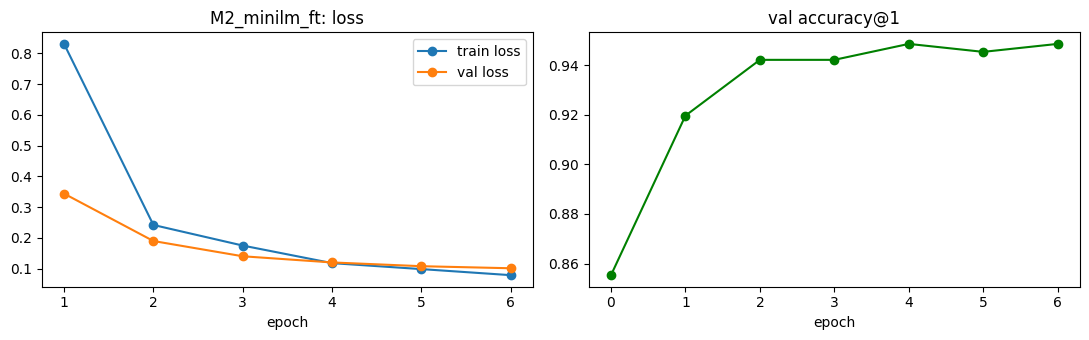

In [6]:
start = time.time()
minilm_ft, history = train_bi_encoder(MINILM, train, val, answer_bank, pair_types=("q2q", "q2a"),
                                      eval_mode="q2q", max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED)
print(f"training time: {time.time() - start:.0f}s")
plot_history(history, "M2_minilm_ft")

In [7]:
for mode in ["q2q", "q2a"]:
    retriever = EmbeddingRetriever(minilm_ft, mode=mode).fit(train["question"], train["intent_id"], answer_bank)
    record(f"M2_minilm_ft_both_{mode}", retriever, f"MiniLM fine-tuned on q2q+q2a pairs, MNRL, match {mode}")

# Save to disk and free GPU memory before the next experiments
minilm_ft.save("models/M2_minilm_ft_both")
del minilm_ft, retriever
free_memory()

M2_minilm_ft_both_q2q            val acc@1 0.949 | test acc@1 0.940 | test MRR 0.959 | test macro-F1 0.808
M2_minilm_ft_both_q2a            val acc@1 0.891 | test acc@1 0.859 | test MRR 0.920 | test macro-F1 0.789


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 4. Experiment 2 – Which pairs to train on?
Same model, trained on only one pair type, evaluated with the matching mode it was trained for.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

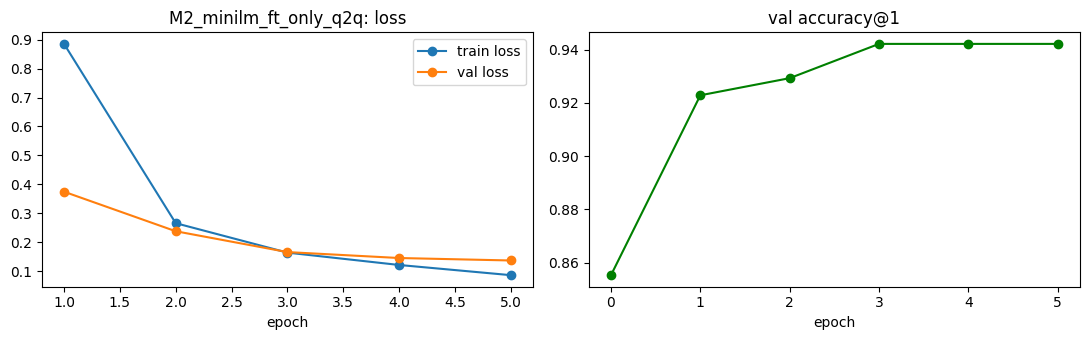

M2_minilm_ft_only_q2q            val acc@1 0.942 | test acc@1 0.934 | test MRR 0.955 | test macro-F1 0.792


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

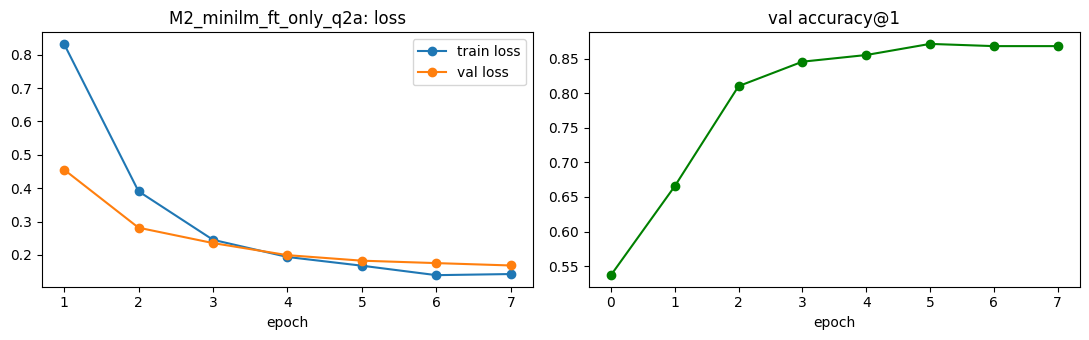

M2_minilm_ft_only_q2a            val acc@1 0.871 | test acc@1 0.835 | test MRR 0.906 | test macro-F1 0.752


In [8]:
for pair_type in ["q2q", "q2a"]:
    model, history = train_bi_encoder(MINILM, train, val, answer_bank, pair_types=(pair_type,),
                                      eval_mode=pair_type, max_epochs=MAX_EPOCHS, patience=PATIENCE,
                                      seed=SEED, verbose=False)
    plot_history(history, f"M2_minilm_ft_only_{pair_type}")
    retriever = EmbeddingRetriever(model, mode=pair_type).fit(train["question"], train["intent_id"], answer_bank)
    record(f"M2_minilm_ft_only_{pair_type}", retriever, f"MiniLM fine-tuned on {pair_type} pairs only, match {pair_type}")
    del model, retriever
    free_memory()

## 5. Experiment 3 – Biomedical model: PubMedBERT embeddings
PubMedBERT was pre-trained on biomedical papers (PubMed). Does medical vocabulary help with
everyday questions from young people? (It is ~5x larger than MiniLM: 110M vs 22M parameters.)

In [9]:
for mode in ["q2q", "q2a"]:
    retriever = EmbeddingRetriever(PUBMEDBERT, mode=mode).fit(train["question"], train["intent_id"], answer_bank)
    record(f"M3_pubmedbert_frozen_{mode}", retriever, f"pubmedbert-base-embeddings, no training, match {mode}")
del retriever
free_memory()

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/6.33k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

M3_pubmedbert_frozen_q2q         val acc@1 0.678 | test acc@1 0.712 | test MRR 0.798 | test macro-F1 0.526


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

M3_pubmedbert_frozen_q2a         val acc@1 0.367 | test acc@1 0.390 | test MRR 0.543 | test macro-F1 0.355


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

epoch 0 (before training): val acc@1 = 0.678
epoch 1: train loss 0.8463 | val loss 0.3264 | val acc@1 0.926 | 120.8s
epoch 2: train loss 0.1867 | val loss 0.1386 | val acc@1 0.929 | 123.4s
epoch 3: train loss 0.1067 | val loss 0.0970 | val acc@1 0.952 | 119.9s
epoch 4: train loss 0.0697 | val loss 0.0752 | val acc@1 0.958 | 115.0s
epoch 5: train loss 0.0521 | val loss 0.0693 | val acc@1 0.952 | 118.7s
epoch 6: train loss 0.0355 | val loss 0.0702 | val acc@1 0.958 | 121.7s
early stopping: no improvement for 2 epochs
training time: 725s


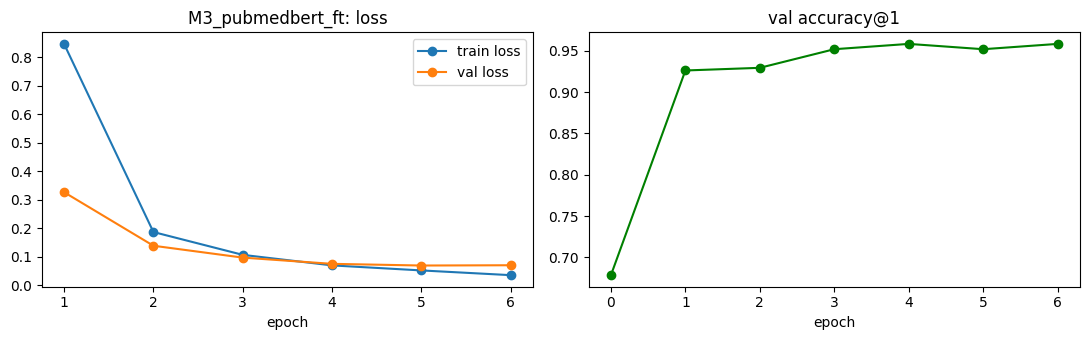

M3_pubmedbert_ft_both_q2q        val acc@1 0.958 | test acc@1 0.952 | test MRR 0.968 | test macro-F1 0.835


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [10]:
start = time.time()
pubmed_ft, history = train_bi_encoder(PUBMEDBERT, train, val, answer_bank, pair_types=("q2q", "q2a"),
                                      eval_mode="q2q", max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED)
print(f"training time: {time.time() - start:.0f}s")
plot_history(history, "M3_pubmedbert_ft")
retriever = EmbeddingRetriever(pubmed_ft, mode="q2q").fit(train["question"], train["intent_id"], answer_bank)
record("M3_pubmedbert_ft_both_q2q", retriever, "PubMedBERT fine-tuned on q2q+q2a pairs, MNRL, match q2q")
pubmed_ft.save("models/M3_pubmedbert_ft_both")
del pubmed_ft, retriever
free_memory()

## 6. Fine-tuned DistilBERT classifier
A different design: instead of comparing with known questions, the model directly outputs one
probability per intent (a classification layer on top of DistilBERT, trained with cross-entropy).
The warning about newly initialised weights is expected: that is the new classification layer.

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 4.4752 | val loss 4.1512 | val acc@1 0.113 | 5.4s
epoch 2: train loss 3.2971 | val loss 2.3563 | val acc@1 0.650 | 5.4s
epoch 3: train loss 1.6510 | val loss 1.2314 | val acc@1 0.794 | 5.4s
epoch 4: train loss 0.8907 | val loss 0.8209 | val acc@1 0.852 | 5.5s
epoch 5: train loss 0.5718 | val loss 0.6341 | val acc@1 0.904 | 5.7s
epoch 6: train loss 0.4012 | val loss 0.5020 | val acc@1 0.916 | 5.6s
epoch 7: train loss 0.2921 | val loss 0.4405 | val acc@1 0.929 | 5.5s
epoch 8: train loss 0.2250 | val loss 0.3990 | val acc@1 0.929 | 5.4s
epoch 9: train loss 0.1806 | val loss 0.3684 | val acc@1 0.926 | 5.4s
epoch 10: train loss 0.1560 | val loss 0.3615 | val acc@1 0.936 | 5.4s
epoch 11: train loss 0.1321 | val loss 0.3411 | val acc@1 0.939 | 5.3s
epoch 12: train loss 0.1190 | val loss 0.3350 | val acc@1 0.932 | 5.3s
epoch 13: train loss 0.1080 | val loss 0.3276 | val acc@1 0.932 | 5.4s
epoch 14: train loss 0.1005 | val loss 0.3263 | val acc@1 0.936 | 5.3s
early stopping:

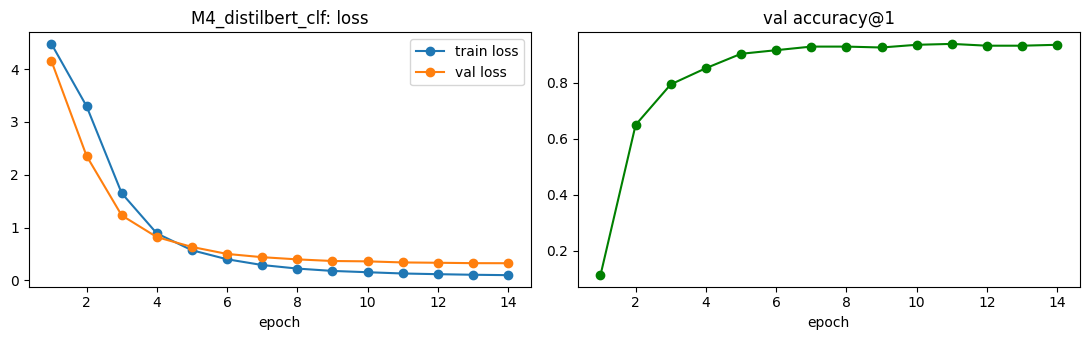

M4_distilbert_clf                val acc@1 0.939 | test acc@1 0.940 | test MRR 0.952 | test macro-F1 0.764


In [11]:
start = time.time()
distilbert_clf, history = train_classifier(DISTILBERT, train, val, batch_size=16, lr=5e-5,
                                           max_epochs=15, patience=3, seed=SEED)
print(f"training time: {time.time() - start:.0f}s")
plot_history(history, "M4_distilbert_clf")
record("M4_distilbert_clf", distilbert_clf, "distilbert-base-uncased + classification head, cross-entropy")
del distilbert_clf
free_memory()

## 7. Experiment 4 – Training data size (25% / 50% / 100%)
How much does performance depend on the amount of training data? We keep a fraction of the
training questions **of every intent** (at least 1 each), and compare the fine-tuned MiniLM with
the TF-IDF baseline. Val and test stay exactly the same.

In [12]:
def subsample(data, fraction, seed=SEED):
    """Keep `fraction` of each intent's questions (at least one)."""
    parts = []
    for _, group in data.groupby("intent_id"):
        n = max(1, round(fraction * len(group)))
        parts.append(group.sample(n=n, random_state=seed))
    return pd.concat(parts).reset_index(drop=True)

size_rows = []
for fraction in [0.25, 0.5, 1.0]:
    part = subsample(train, fraction) if fraction < 1 else train
    tag = f"{int(fraction * 100)}pct"

    tfidf = TfidfLogRegBaseline(analyzer="char_wb", ngram_range=(2, 5), C=100.0).fit(part["question"], part["intent_id"])
    record(f"S_tfidf_logreg_{tag}", tfidf, f"TF-IDF char 2-5 + LR, {len(part)} training questions")

    if fraction < 1:
        model, history = train_bi_encoder(MINILM, part, val, answer_bank, pair_types=("q2q", "q2a"),
                                          eval_mode="q2q", max_epochs=MAX_EPOCHS, patience=PATIENCE,
                                          seed=SEED, verbose=False)
        retriever = EmbeddingRetriever(model, mode="q2q").fit(part["question"], part["intent_id"], answer_bank)
        record(f"S_minilm_ft_{tag}", retriever, f"MiniLM fine-tuned q2q+q2a, {len(part)} training questions")
        del model, retriever
        free_memory()
    else:
        results["S_minilm_ft_100pct"] = results["M2_minilm_ft_both_q2q"]  # same run as section 3

    for name in [f"S_tfidf_logreg_{tag}", f"S_minilm_ft_{tag}"]:
        size_rows.append({"model": name.rsplit("_", 1)[0], "train_questions": len(part),
                          "fraction": fraction, "test_accuracy@1": results[name]["test"]["accuracy@1"]})

size_table = pd.DataFrame(size_rows)
size_table

S_tfidf_logreg_25pct             val acc@1 0.572 | test acc@1 0.595 | test MRR 0.704 | test macro-F1 0.405


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

S_minilm_ft_25pct                val acc@1 0.900 | test acc@1 0.886 | test MRR 0.920 | test macro-F1 0.711
S_tfidf_logreg_50pct             val acc@1 0.714 | test acc@1 0.742 | test MRR 0.812 | test macro-F1 0.500


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

S_minilm_ft_50pct                val acc@1 0.942 | test acc@1 0.919 | test MRR 0.944 | test macro-F1 0.763
S_tfidf_logreg_100pct            val acc@1 0.826 | test acc@1 0.823 | test MRR 0.867 | test macro-F1 0.610


,model,train_questions,fraction,test_accuracy@1
0,S_tfidf_logreg,388,0.25,0.594595
1,S_minilm_ft,388,0.25,0.885886
2,S_tfidf_logreg,748,0.50,0.741742
3,S_minilm_ft,748,0.50,0.918919
4,S_tfidf_logreg,1477,1.00,0.822823
5,S_minilm_ft,1477,1.00,0.939940


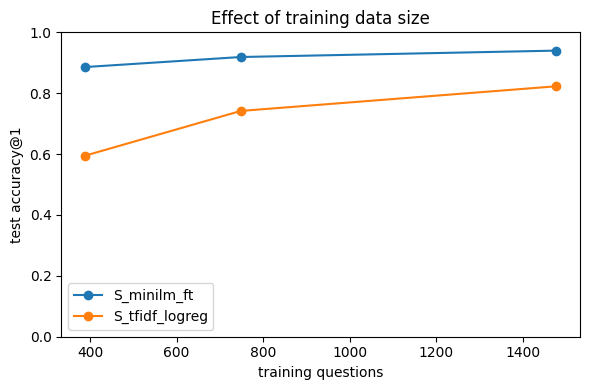

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
for model_name, group in size_table.groupby("model"):
    ax.plot(group["train_questions"], group["test_accuracy@1"], marker="o", label=model_name)
ax.set_xlabel("training questions"); ax.set_ylabel("test accuracy@1"); ax.set_ylim(0, 1)
ax.set_title("Effect of training data size"); ax.legend()
plt.tight_layout()
plt.savefig("results/figures/data_size.png", dpi=150)
plt.show()

## 8. All results

In [14]:
table = pd.read_csv(RESULTS_FILE)
wide = table.pivot_table(index="experiment", columns="split",
                         values=["accuracy@1", "recall@3", "mrr", "macro_f1"], sort=False)
wide.columns = [f"{split}_{metric}" for metric, split in wide.columns]
wide = wide[["val_accuracy@1", "test_accuracy@1", "test_recall@3", "test_mrr", "test_macro_f1"]].sort_values("val_accuracy@1", ascending=False)
wide.round(3)

,val_accuracy@1,test_accuracy@1,test_recall@3,test_mrr,test_macro_f1
experiment,,,,,
M3_pubmedbert_ft_both_q2q,0.958,0.952,0.988,0.968,0.835
M2_minilm_ft_both_q2q,0.949,0.940,0.976,0.959,0.808
S_minilm_ft_50pct,0.942,0.919,0.967,0.944,0.763
M2_minilm_ft_only_q2q,0.942,0.934,0.976,0.955,0.792
M4_distilbert_clf,0.939,0.940,0.961,0.952,0.764
S_minilm_ft_25pct,0.900,0.886,0.946,0.920,0.711
M2_minilm_ft_both_q2a,0.891,0.859,0.985,0.920,0.789
M2_minilm_ft_only_q2a,0.871,0.835,0.979,0.906,0.752
M1_minilm_frozen_q2q,0.855,0.844,0.940,0.896,0.688


In [15]:
# Markdown version of the table for the README / report
with open("results/experiments.md", "w") as f:
    f.write(wide.round(3).reset_index().to_markdown(index=False))
print(open("results/experiments.md").read())

| experiment                |   val_accuracy@1 |   test_accuracy@1 |   test_recall@3 |   test_mrr |   test_macro_f1 |
|:--------------------------|-----------------:|------------------:|----------------:|-----------:|----------------:|
| M3_pubmedbert_ft_both_q2q |            0.958 |             0.952 |           0.988 |      0.968 |           0.835 |
| M2_minilm_ft_both_q2q     |            0.949 |             0.94  |           0.976 |      0.959 |           0.808 |
| S_minilm_ft_50pct         |            0.942 |             0.919 |           0.967 |      0.944 |           0.763 |
| M2_minilm_ft_only_q2q     |            0.942 |             0.934 |           0.976 |      0.955 |           0.792 |
| M4_distilbert_clf         |            0.939 |             0.94  |           0.961 |      0.952 |           0.764 |
| S_minilm_ft_25pct         |            0.9   |             0.886 |           0.946 |      0.92  |           0.711 |
| M2_minilm_ft_both_q2a     |            0.891 |        

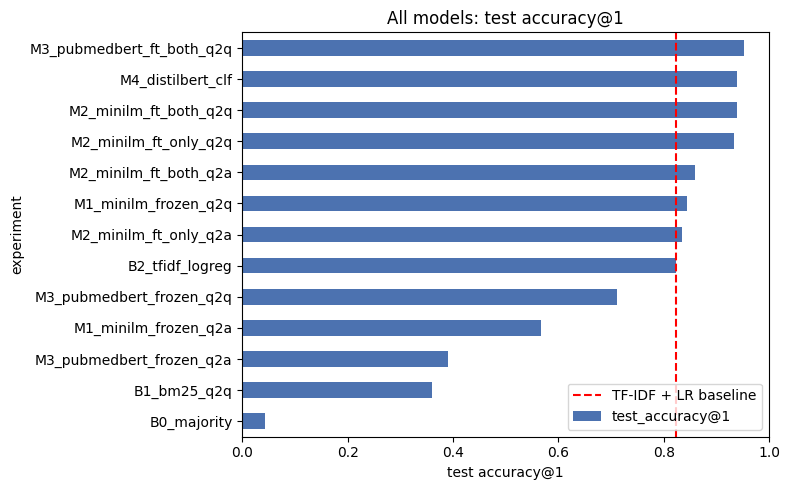

In [16]:
main = [e for e in wide.index if not e.startswith("S_")]
ax = wide.loc[main, "test_accuracy@1"].sort_values().plot.barh(figsize=(8, 5), color="#4C72B0")
ax.axvline(wide.loc["B2_tfidf_logreg", "test_accuracy@1"], color="red", linestyle="--", label="TF-IDF + LR baseline")
ax.set_xlabel("test accuracy@1"); ax.set_xlim(0, 1); ax.legend(loc="lower right")
ax.set_title("All models: test accuracy@1")
plt.tight_layout()
plt.savefig("results/figures/all_models_test_accuracy.png", dpi=150)
plt.show()

## 9. Save the best model (chosen by **val** accuracy, not test)
Saved to `models/` (git-ignored). Phase 5 (error analysis) and Phase 6 (the app) load it from there.

In [17]:
import shutil

candidates = {  # experiment name -> folder where that fine-tuned model was saved
    "M2_minilm_ft_both_q2q": "models/M2_minilm_ft_both",
    "M3_pubmedbert_ft_both_q2q": "models/M3_pubmedbert_ft_both",
}
best_name = max(candidates, key=lambda name: results[name]["val"]["accuracy@1"])
print("Best bi-encoder by val accuracy@1:", best_name, round(results[best_name]["val"]["accuracy@1"], 3))
print("DistilBERT classifier val accuracy@1:", round(results["M4_distilbert_clf"]["val"]["accuracy@1"], 3))
shutil.copytree(candidates[best_name], "models/best_bi_encoder", dirs_exist_ok=True)
print("copied to models/best_bi_encoder")

Best bi-encoder by val accuracy@1: M3_pubmedbert_ft_both_q2q 0.958
DistilBERT classifier val accuracy@1: 0.939
copied to models/best_bi_encoder


## 10. Colab only: download the outputs
Downloads two zip files: `results.zip` (tables, figures, training logs) and `best_bi_encoder.zip`
(the best model). Also save this notebook with its outputs: **File → Download → Download .ipynb**.
Then put them in the project folder on your computer (see the README / instructions).

In [18]:
if IN_COLAB:
    import shutil
    from google.colab import files

    shutil.make_archive("/content/results", "zip", root_dir="/content/repo", base_dir="results")
    shutil.make_archive("/content/best_bi_encoder", "zip", root_dir="/content/repo/models", base_dir="best_bi_encoder")
    files.download("/content/results.zip")
    files.download("/content/best_bi_encoder.zip")
else:
    print("Running locally: outputs are already in results/ and models/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Observations (fill in after running)
- Did fine-tuning beat the frozen model and the TF-IDF baseline? By how much?
- q2q vs q2a: which matching works better, and why?
- Did the biomedical model help?
- Training curves: where does val stop improving? Any sign of overfitting?
- How does performance change with less data?